In [1]:
from notebook_cache import NotebookCache

# results and prints live on disk, so they survive kernel restarts; one folder per notebook
cache = NotebookCache('../cache/act_namespace')

# ACT, built forward (namespace + cache)

Redo of `act_dict.ipynb` with `SimpleNamespace` in place of dict/frozendict: a bundle read later is a **namespace**, so it reads `b.state`, not `b['state']`, and the fork types each attribute from how it's built. A small return unpacked right away stays a **tuple**. Where a namespace goes into a function, its parameter is a `Protocol`. Same data, split and eval seeds as `act.ipynb`.

### step 0 — the data, as in BC


In [2]:
from pathlib import Path
from types import SimpleNamespace as namespace

import numpy as np
from lerobot.datasets.lerobot_dataset import LeRobotDataset
from numpy.typing import NDArray

np.set_printoptions(precision=3, suppress=True)
REPO = Path.cwd().parent

In [3]:
@cache
def load_table():
    # straight from the table, no video decode
    ds = LeRobotDataset('dream_robot/pick_place_cube', root=REPO / 'data/robosuite/pick_place_cube')
    return (
        np.asarray(ds.hf_dataset['observation.state'], dtype=np.float32),  # state [N, 8]
        np.asarray(ds.hf_dataset['action'], dtype=np.float32),  # action [N, 8]
        np.asarray(ds.hf_dataset['episode_index'], dtype=np.int64),  # episode [N], which demo
    )

load_table: cached, 1 call(s) stored


In [4]:
state, action, episode = load_table()  # three arrays, unpacked once: a tuple reads fine
val_eps = np.random.default_rng(0).permutation(25)[:5]  # same 5 held-out demos as bc_2 and act
is_val = np.isin(episode, val_eps)  # [N]
print(f'{state.shape=}  {action.shape=}  {val_eps=}  train {(~is_val).sum()}  val {is_val.sum()}')

state.shape=(5288, 8)  action.shape=(5288, 8)  val_eps=array([19,  4, 10, 11, 24])  train 4218  val 1070


### step 1 — the target is a chunk: the next K actions, not one


In [5]:
def make_chunks(action: NDArray[np.float32], episode: NDArray[np.int64], K: int):
    # demo e's last row is where its run of rows ends, since demos are stored in order
    assert (np.diff(episode) >= 0).all(), 'demos not stored in order'
    last = np.searchsorted(episode, episode, side='right') - 1  # [N]
    idx = np.arange(len(action))[:, None] + np.arange(K)  # [N, K], rows t .. t+K-1
    pad = idx > last[:, None]  # [N, K], True where the chunk runs past its demo's end
    chunks = action[
        np.minimum(idx, last[:, None])
    ]  # [N, K, 8], past the end: repeat the final action
    return chunks, pad


K = 50  # chunk length: 50 steps = 1.7 s at 30 Hz; a demo is ~210 steps
chunks, pad = make_chunks(action, episode, K)  # two arrays, unpacked at once: a tuple
print(f'{chunks.shape=}  {pad.shape=}')
print(f'frames whose chunk is partly padding: {pad.any(1).sum()} of {len(action)}')

chunks.shape=(5288, 50, 8)  pad.shape=(5288, 50)
frames whose chunk is partly padding: 1225 of 5288


### step 2 — what a chunk looks like


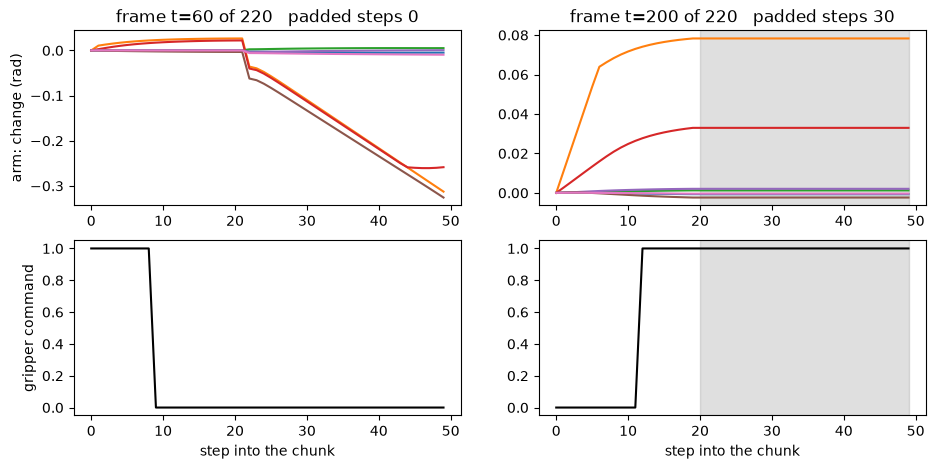

In [6]:
import matplotlib.pyplot as plt

rows = np.flatnonzero(episode == 2)  # demo 2's frames, as in bc_2
fig = plt.figure(figsize=(11, 5))
arm = [fig.add_subplot(2, 2, 1 + col) for col in range(2)]  # top row: 7 arm joints
grip = [fig.add_subplot(2, 2, 3 + col, sharex=arm[col]) for col in range(2)]  # bottom row: gripper
for col, t in enumerate([60, len(rows) - 20]):  # mid-demo, and 20 steps before the end
    ch = chunks[rows[t]]  # [K, 8], the plan from frame t
    arm[col].plot(ch[:, :7] - ch[0, :7])  # as change from the chunk's first action
    grip[col].plot(ch[:, 7], color='k')  # gripper command: 1 open, 0 close
    n_pad = int(pad[rows[t]].sum())
    if n_pad:
        for a in (arm[col], grip[col]):
            a.axvspan(
                K - n_pad, K - 1, color='grey', alpha=0.25
            )  # padded: repeats the final action
    arm[col].set_title(f'frame t={t} of {len(rows)}   padded steps {n_pad}')
    grip[col].set_xlabel('step into the chunk')
arm[0].set_ylabel('arm: change (rad)')
grip[0].set_ylabel('gripper command')
plt.show()

### step 3 — both cameras into RAM (~20 s the first time, cached after)


In [7]:
import torch
from torch import Tensor

In [8]:
@cache
def load_images():
    # every frame decoded from both videos once, kept as uint8 (~0.5 GB), as bc_2 steps 8 and 21
    ds = LeRobotDataset('dream_robot/pick_place_cube', root=REPO / 'data/robosuite/pick_place_cube')
    top = np.zeros((len(ds), 3, 128, 128), dtype=np.uint8)  # [N, 3, H, W]
    wrist = np.zeros_like(top)
    for i in range(len(ds)):
        top[i] = (ds[i]['observation.images.top'] * 255).round().to(torch.uint8).numpy()
        wrist[i] = (ds[i]['observation.images.wrist'] * 255).round().to(torch.uint8).numpy()
    return top, wrist

load_images: cached, 1 call(s) stored


In [9]:
top, wrist = load_images()  # two arrays, unpacked at once: a tuple
print(f'{top.shape=}  {wrist.shape=}')

top.shape=(5288, 3, 128, 128)  wrist.shape=(5288, 3, 128, 128)


### step 4 — to the GPU, plus normalisation stats

The first bundles read by name in later cells (`data.chunks.train`, `stats.action.std`), so namespaces, nested. No annotations: each attribute's type comes from what built it, through `to_gpu` and `mean_std`'s inferred returns.


In [10]:
dev = 'cuda'


def to_gpu(x: NDArray) -> namespace:
    # split once by episode; images stay uint8 until a batch is drawn
    return namespace(train=torch.tensor(x[~is_val]).to(dev), val=torch.tensor(x[is_val]).to(dev))


def mean_std(x: Tensor, dims: tuple[int, ...]) -> namespace:
    # keepdim leaves a 1 for each reduced dim, so the stats broadcast straight back over x
    return namespace(mean=x.mean(dims, keepdim=True), std=x.std(dims, keepdim=True))


data = namespace(
    top=to_gpu(top),
    wrist=to_gpu(wrist),
    state=to_gpu(state),
    chunks=to_gpu(chunks),
    pad=to_gpu(pad),
)

# from train only, as bc_2 steps 19 and 22. Action stats from single actions: a chunk is made of
# the same actions, so they apply to every step of it (chunk step 0 = that frame's action).
# State and action stats are [1, 8] each; image stats [1, 3, 1, 1], from every 20th frame
stats = namespace(
    state=mean_std(data.state.train, (0,)),
    action=mean_std(data.chunks.train[:, 0], (0,)),
    top=mean_std(data.top.train[::20].float() / 255, (0, 2, 3)),
    wrist=mean_std(data.wrist.train[::20].float() / 255, (0, 2, 3)),
)
print(f'{data.chunks.train.shape=}  {data.chunks.val.shape=}  {data.pad.train.shape=}')
print('action std', stats.action.std.cpu().numpy())

data.chunks.train.shape=torch.Size([4218, 50, 8])  data.chunks.val.shape=torch.Size([1070, 50, 8])  data.pad.train.shape=torch.Size([4218, 50])
action std [[0.158 0.191 0.035 0.135 0.06  0.161 0.196 0.48 ]]


### step 5 — BC's image encoder, as in bc_2


In [11]:
from torch import nn


# bc_2's image encoder, unchanged: conv stack (step 9) without its last ReLU, then spatial softmax (step 15)
def make_conv() -> nn.Sequential:
    return nn.Sequential(
        nn.Conv2d(3, 32, 5, 2, 2),  # -> [B, 32, 64, 64]
        nn.ReLU(),
        nn.Conv2d(32, 64, 3, 2, 1),  # -> [B, 64, 32, 32]
        nn.ReLU(),
        nn.Conv2d(64, 128, 3, 2, 1),  # -> [B, 128, 16, 16]
        nn.ReLU(),
        nn.Conv2d(128, 64, 3, 1, 1),  # -> [B, 64, 16, 16], no ReLU: the softmax wants negatives
    )


class SpatialSoftmax(nn.Module):
    cell_x: Tensor  # buffers, declared so the checker doesn't read them as Tensor | Module
    cell_y: Tensor

    def __init__(self, h: int, w: int):
        super().__init__()
        self.log_t = nn.Parameter(torch.zeros(()))  # learned temperature, T = exp(log_t) > 0
        self.register_buffer('cell_x', torch.linspace(-1, 1, w).repeat(h))  # [H*W]
        self.register_buffer('cell_y', torch.linspace(-1, 1, h).repeat_interleave(w))  # [H*W]

    def forward(self, f: Tensor) -> Tensor:
        # f: [B, C, H, W] feature maps
        # out: [B, 2C], an (x, y) per map
        B, C, H, W = f.shape
        p = torch.softmax(f.reshape(B, C, H * W) / self.log_t.exp(), dim=-1)  # [B, C, H*W]
        return torch.stack([p @ self.cell_x, p @ self.cell_y], dim=-1).reshape(B, 2 * C)


enc = nn.Sequential(make_conv(), SpatialSoftmax(16, 16)).to(dev)
x = data.top.train[:4].float() / 255  # [4, 3, 128, 128]
# [4, 128]: 64 maps -> 64 (x, y) points
points = enc((x - stats.top.mean) / stats.top.std)
print(f'{x.shape} -> {points.shape}')

torch.Size([4, 3, 128, 128]) -> torch.Size([4, 128])


### step 6 — `ChunkNet`: BC's net, but the head outputs a chunk


In [12]:
class ChunkNet(nn.Module):
    # bc_2's TwoCamNet (step 23) with one change: the head outputs K actions, not 1
    def __init__(self):
        super().__init__()
        self.top = nn.Sequential(make_conv(), SpatialSoftmax(16, 16))
        self.wrist = nn.Sequential(make_conv(), SpatialSoftmax(16, 16))
        self.head = nn.Sequential(nn.Linear(128 * 2 + 8, 512), nn.ReLU(), nn.Linear(512, K * 8))

    def forward(self, top: Tensor, wrist: Tensor, state: Tensor) -> Tensor:
        # top, wrist: [B, 3, 128, 128] floats in [0, 1]
        # state: [B, 8] radians
        # out: [B, K, 8] radians, the next K actions
        f_top = self.top((top - stats.top.mean) / stats.top.std)  # [B, 128]
        f_wrist = self.wrist((wrist - stats.wrist.mean) / stats.wrist.std)  # [B, 128]
        st = (state - stats.state.mean) / stats.state.std
        out = self.head(torch.cat([f_top, f_wrist, st], dim=-1))  # [B, 264] -> [B, K*8]
        out = out.reshape(-1, K, 8)  # [B, K, 8] in std units
        # [1, 8] stats broadcast over every chunk step
        return out * stats.action.std + stats.action.mean


net = ChunkNet().to(dev)
print('params', sum(p.numel() for p in net.parameters()))
i = torch.arange(4, device=dev)
pred = net(data.top.train[i].float() / 255, data.wrist.train[i].float() / 255, data.state.train[i])
print(pred.shape)  # [4, K, 8]

params 678034
torch.Size([4, 50, 8])


### step 7 — the loss: L1 over the chunk, padded steps skipped

The split is picked by a variable, so a small `take(x)` picks `x.train` or `x.val`. Its `-> Tensor` is the only annotation needed: the fork infers the batch from what `get_batch` returns, a 5-attribute namespace of Tensors, read as `b.top`, `b.pad` below and in training.


In [13]:
from typing import Literal


def get_batch(split: Literal['train', 'val'], i: Tensor) -> namespace:
    # rows i of one split, every field at once; images to floats in [0, 1] only now
    def take(x) -> Tensor:  # x: a train/val pair; -> Tensor types every field of the batch
        return (x.train if split == 'train' else x.val)[i]

    return namespace(
        top=take(data.top).float() / 255,  # [B, 3, 128, 128]
        wrist=take(data.wrist).float() / 255,  # [B, 3, 128, 128]
        state=take(data.state),  # [B, 8]
        chunks=take(data.chunks),  # [B, K, 8]
        pad=take(data.pad),  # [B, K] bool
    )


def chunk_l1(pred: Tensor, target: Tensor, pad: Tensor) -> Tensor:
    # pred, target: [B, K, 8] radians
    # pad: [B, K] bool, True where the step is padding past the demo's end
    # out: [], mean |error| in std units (bc_2 step 20) over real steps only
    err = ((pred - target) / stats.action.std).abs()  # [B, K, 8]
    keep = (~pad)[..., None].float()  # [B, K, 1], 0 on padded steps
    return (err * keep).sum() / (keep.sum() * 8)  # divide by the number of real values, not B*K*8


torch.manual_seed(0)
b = get_batch(
    'train', torch.randint(0, len(data.state.train), (64,), device=dev)
)  # 64 random frames
with torch.no_grad():
    pred = net(b.top, b.wrist, b.state)  # [64, K, 8]
print(f'padded steps in this batch: {b.pad.float().mean():.0%}')
print(f'untrained loss {chunk_l1(pred, b.chunks, b.pad):.3f}')

padded steps in this batch: 7%
untrained loss 0.797


### step 8 — train `ChunkNet` (~45 s the first time, cached after)


In [14]:
import torch.nn.functional as F


def random_shift(x: Tensor, pad: int = 4) -> Tensor:
    # as bc_2 step 30
    # x: [B, 3, H, W]
    # out: [B, 3, H, W], the whole batch moved by up to pad px each way, edge pixels repeated
    B, C, H, W = x.shape
    x = F.pad(x, (pad, pad, pad, pad), mode='replicate')  # [B, 3, H + 2p, W + 2p]
    dy, dx = (int(d) for d in torch.randint(0, 2 * pad + 1, (2,)))
    return x[:, :, dy : dy + H, dx : dx + W]


@torch.no_grad()
def val_error(net: nn.Module) -> Tensor:
    # out: [8], mean |error| of each chunk's FIRST action on val, radians, comparable with bc_2.
    # 256 frames at a time, never shifted
    n = len(data.state.val)
    firsts = []
    for j in range(0, n, 256):
        b = get_batch('val', torch.arange(j, min(j + 256, n), device=dev))
        pred = net(b.top, b.wrist, b.state)  # [<=256, K, 8]
        firsts.append(pred[:, 0])
    return (torch.cat(firsts) - data.chunks.val[:, 0]).abs().mean(0)

In [15]:
@cache
def train(seed: int = 0, steps: int = 3000, shift: int = 4, lr: float = 1e-3) -> namespace:
    # bc_2's train() with the chunk loss; both cameras, normalised, shifted
    torch.manual_seed(seed)
    net = ChunkNet().to(dev)
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    err = torch.zeros(8)
    for step in range(steps + 1):
        b = get_batch('train', torch.randint(0, len(data.state.train), (64,), device=dev))
        pred = net(random_shift(b.top, shift), random_shift(b.wrist, shift), b.state)
        loss = chunk_l1(pred, b.chunks, b.pad)
        opt.zero_grad()
        loss.backward()
        opt.step()
        if step % 500 == 0:
            err = val_error(net).cpu()
            print(
                f'{step:5d}  train {loss.item():.4f}  val arm {err[:7].mean():.4f}  gripper {err[7]:.4f}'
            )
    # weights on the CPU, so the cache holds no GPU tensors; read as .weights, .err in later steps
    return namespace(weights={k: v.cpu() for k, v in net.state_dict().items()}, err=err)

train: cached, 1 call(s) stored


In [16]:
run = train(seed=0)
net = ChunkNet().to(dev)
net.load_state_dict(run.weights)

    0  train 0.7986  val arm 0.1144  gripper 0.4600
  500  train 0.1159  val arm 0.0097  gripper 0.0815
 1000  train 0.0872  val arm 0.0086  gripper 0.0620
 1500  train 0.0700  val arm 0.0079  gripper 0.0558
 2000  train 0.0612  val arm 0.0065  gripper 0.0492
 2500  train 0.0650  val arm 0.0073  gripper 0.0449
 3000  train 0.0576  val arm 0.0064  gripper 0.0461


<All keys matched successfully>

### step 9 — the sim, and `predict(obs)`: one observation in, a chunk out


In [17]:
import logging
import os

# render without a window; must be set before mujoco loads
os.environ.setdefault('MUJOCO_GL', 'egl')

logging.disable(logging.WARNING)  # robosuite warns while importing; mute that
import robosuite

logging.disable(logging.NOTSET)
logging.getLogger('robosuite_logs').setLevel(logging.ERROR)

from dream_robot.core.env_api import Env
from dream_robot.core.registry import make_env
from dream_robot.core.schema import Observation

# as bc_2 steps 25-26
env: Env = make_env('robosuite/pick_place_cube')


def frame(im: np.ndarray) -> Tensor:
    # im: [H, W, 3] uint8 from the sim
    # out: [1, 3, H, W] floats in [0, 1] on the GPU
    return torch.from_numpy(im).permute(2, 0, 1)[None].to(dev).float() / 255


@torch.no_grad()
def predict(obs: Observation, model: nn.Module | None = None) -> NDArray[np.float32]:
    # model: the net to ask, the global net if None
    # out: [K, 8], the plan from this observation
    model = model or net
    st = torch.from_numpy(obs.state)[None].to(dev)  # [1, 8]
    chunk = model(frame(obs.images['top']), frame(obs.images['wrist']), st)
    plan = chunk[0].cpu().numpy()  # [K, 8]
    plan[:, 7] = np.clip(plan[:, 7], 0.0, 1.0)  # gripper commands must stay in [0, 1]
    return plan


net.eval()
print(predict(env.reset(seed=1000)).shape)

(50, 8)


### step 10 — play the chunk: n actions blind, then re-plan

`Outcome` crosses into a parameter annotation (`score(results: list[Outcome])`), so it's a class: a `NamedTuple`. Still a tuple, so it unpacks as `ok, mode, steps`, and `.success` works in every checker.


In [18]:
from collections import Counter
from typing import NamedTuple


class Outcome(NamedTuple):  # how one rollout ended
    success: bool
    mode: str
    steps: int


def score(results: list[Outcome]) -> str:
    # 'wins/n   failures {mode: count}'
    wins = sum(r.success for r in results)
    fails = Counter(r.mode for r in results if not r.success)
    return f'{wins:2d}/{len(results)}   failures {dict(fails)}'


def rollout(seed: int, n_exec: int) -> Outcome:
    # predict a chunk, play its first n_exec actions without looking, then predict again
    obs = env.reset(seed=seed)
    plan = []  # actions still to play from the last chunk
    for step in range(600):
        if not plan:
            plan = list(predict(obs)[:n_exec])  # n_exec x [8]
        r = env.step(plan.pop(0))
        obs = r.observation
        if r.terminated or r.truncated:
            return Outcome(r.success, str(r.failure_mode), step + 1)
    return Outcome(False, 'no_end', 600)


# re-plan every 10 steps = 3 times a second
ok, mode, steps = rollout(1000, n_exec=10)
print(f'seed 1000: {"SUCCESS" if ok else mode}  after {steps} steps')

seed 1000: SUCCESS  after 202 steps


### step 11 — how many steps to play blind? 20 seeds each (~5 min the first time, cached after)


In [19]:
@cache
def sweep(n_exec: int):
    # the same 20 unseen seeds as bc_2, each rolled out playing n_exec actions per chunk
    results = [rollout(seed, n_exec=n_exec) for seed in range(1000, 1020)]
    print(f'n_exec {n_exec:2d}: {score(results)}')
    return results

sweep: cached, 5 call(s) stored


In [20]:
# n_exec = 1 re-plans every step and uses only the first action, the way BC acts;
# 50 plays every chunk to its end
results = {n_exec: sweep(n_exec) for n_exec in [1, 5, 10, 25, 50]}

n_exec  1:  0/20   failures {'no_grasp': 20}
n_exec  5:  2/20   failures {'no_grasp': 15, 'dropped': 3}
n_exec 10: 13/20   failures {'no_grasp': 6, 'wrong_target': 1}
n_exec 25: 18/20   failures {'wrong_target': 1, 'no_grasp': 1}
n_exec 50:  8/20   failures {'no_grasp': 11, 'dropped': 1}


### step 12 — temporal ensembling: re-plan every step, average the overlapping plans (~2 min the first time)


In [21]:
def rollout_ensemble(seed: int, m: float = 0.01, model: nn.Module | None = None) -> Outcome:
    # re-plan every step, but play the weighted average of every chunk that covers this step.
    # The chunk made at step s predicts step t as its row t - s, so up to K chunks have a say.
    # Weight exp(-m * i) with i = 0 for the OLDEST chunk (the ACT paper's choice, m = 0.01):
    # old plans count slightly more, so one jumpy new prediction can't swing the arm
    obs = env.reset(seed=seed)
    plans = []  # (made, chunk): the step it was predicted at, and the chunk; oldest first
    for step in range(600):
        plans.append((step, predict(obs, model)))
        plans = [
            (made, chunk) for made, chunk in plans if step - made < K
        ]  # drop chunks that ended before now
        # [n, 8], every plan's guess for now
        preds = np.stack([chunk[step - made] for made, chunk in plans])
        w = np.exp(-m * np.arange(len(preds)))  # [n], oldest first
        action = (w[:, None] * preds).sum(0) / w.sum()  # [8], weighted average
        r = env.step(action)
        obs = r.observation
        if r.terminated or r.truncated:
            return Outcome(r.success, str(r.failure_mode), step + 1)
    return Outcome(False, 'no_end', 600)

In [22]:
@cache
def ensemble(m: float):
    # the same 20 unseen seeds, ensembling with weight width m
    results = [rollout_ensemble(seed, m=m) for seed in range(1000, 1020)]
    print(f'ensemble m={m}: {score(results)}')
    print(
        'steps of the successes:',
        sorted(r.steps for r in results if r.success),
    )
    return results

ensemble: cached, 1 call(s) stored


In [23]:
results_ens = ensemble(0.01)

ensemble m=0.01: 18/20   failures {'wrong_target': 2}
steps of the successes: [196, 199, 202, 204, 206, 207, 208, 210, 210, 211, 211, 212, 212, 213, 214, 219, 222, 436]


### step 13 — film the `wrong_target` failure

Step 12's net (one training run) put the cube in the wrong place on 2 of 20 seeds; replay the first, filmed.


In [24]:
from IPython.display import Video, display

from dream_robot.core.video import observation_panel, write_video

bad = [seed for seed, r in zip(range(1000, 1020), results_ens) if r.mode == 'wrong_target']
print('wrong_target seeds:', bad)

seed = bad[0]
obs = env.reset(seed=seed)
plans = []
frames = []  # [H, W, 3] each: wide view + the policy's two cameras
outcome = Outcome(False, 'no_end', 600)
for step in range(600):
    frames.append(observation_panel(env.render(), obs.images))
    # step 12's ensembling, inline so we can film it
    plans.append((step, predict(obs)))
    plans = [(made, chunk) for made, chunk in plans if step - made < K]
    preds = np.stack([chunk[step - made] for made, chunk in plans])  # [n, 8]
    w = np.exp(-0.01 * np.arange(len(preds)))  # [n]
    action = (w[:, None] * preds).sum(0) / w.sum()
    r = env.step(action)
    obs = r.observation
    if r.terminated or r.truncated:
        outcome = Outcome(r.success, str(r.failure_mode), step + 1)
        break
print(f'replay: {"SUCCESS" if outcome.success else outcome.mode} after {outcome.steps} steps')
video = write_video(
    frames, REPO / f'scratch/act_namespace/wrong_target_seed{seed}.mp4', fps=env.control_hz
)
# embedded in the notebook, so it plays without the file
display(Video(video, embed=True, width=720))

wrong_target seeds: [1005, 1018]
replay: wrong_target after 600 steps


**Seed 1005: grasp and carry work, the release never comes.**

- By step ~100 the cube is in the gripper; by ~200 it's over the bin's near rim.
- From there to step 600 the arm hovers at the rim, cube still held, never lowering into the bin or opening.
- So `wrong_target` here means "timed out holding the cube next to the bin", not "put it in the wrong place".


## ACT's architecture, one piece at a time

Ensembling's direction (oldest- vs newest-first) is skipped this time: act.ipynb steps 17-18 found width matters, direction doesn't.

### step 14 — an image becomes a grid of tokens, not 64 points


In [25]:
D = 256  # token width, the transformer's working size


def make_backbone() -> nn.Sequential:
    # BC's conv stack with one more stride-2 layer, so 128 px -> an 8x8 grid
    # (16x16 = 256 tokens per camera would make attention ~16x slower), then a
    # 1x1 conv that turns each cell's 128 features into one D-wide token
    return nn.Sequential(
        nn.Conv2d(3, 32, 5, 2, 2),  # -> [B, 32, 64, 64]
        nn.ReLU(),
        nn.Conv2d(32, 64, 3, 2, 1),  # -> [B, 64, 32, 32]
        nn.ReLU(),
        nn.Conv2d(64, 128, 3, 2, 1),  # -> [B, 128, 16, 16]
        nn.ReLU(),
        nn.Conv2d(128, 128, 3, 2, 1),  # -> [B, 128, 8, 8]
        nn.ReLU(),
        nn.Conv2d(128, D, 1),  # -> [B, D, 8, 8], one D-vector per grid cell
    )


x = data.top.train[:4].float() / 255  # [4, 3, 128, 128]
grid = make_backbone().to(dev)(x)  # [4, D, 8, 8]
tokens = grid.flatten(2).transpose(1, 2)  # [4, D, 64] -> [4, 64, D]: 64 tokens, one per cell
print(f'{grid.shape=}  ->  {tokens.shape=}')

grid.shape=torch.Size([4, 256, 8, 8])  ->  tokens.shape=torch.Size([4, 64, 256])


### step 15 — tell each token where its patch was: a 2-D position code

Flattening the grid in step 14 threw away row and column. Attention treats tokens as an unordered set, so without this the cube's patch and the bin's patch are just two vectors with no place.


pos.shape=torch.Size([64, 256])


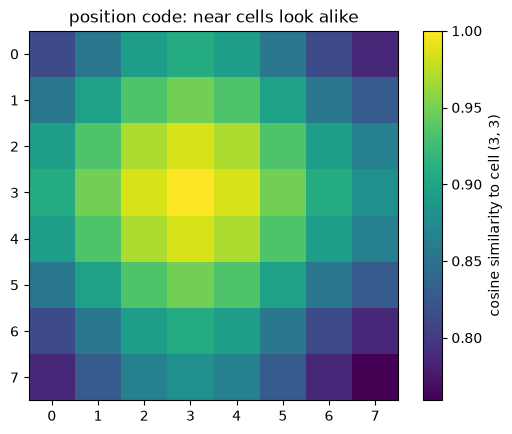

In [26]:
"""
2-D position code for an H × W grid, D numbers per cell:
    first D/2 numbers encode the row, last D/2 the column, each with the
    1-D transformer code. For position p and i = 0 … D/4 − 1:

        ωᵢ      = 10000^(−i / (D/4))                        from 1 down to ~1/10000
        code(p) = [sin(p·ω₀) … sin(p·ω_{D/4−1}),  cos(p·ω₀) … cos(p·ω_{D/4−1})]

    fast frequencies (ω ≈ 1) tell neighbouring cells apart,
    slow ones (ω ≈ 0) change smoothly across the whole grid
"""


def sinusoid_2d(h: int, w: int, d: int) -> Tensor:
    # out: [h*w, d], row-major like the flattened grid in step 14. Fixed, not learned:
    # 25 demos are too few to learn a good code for 64 cells
    q = d // 4
    omega = 10000 ** (-torch.arange(q) / q)  # [q]

    def code(n: int) -> Tensor:  # [n, d/2], the 1-D code for positions 0 .. n-1
        p = torch.arange(n)[:, None] * omega  # [n, q]
        return torch.cat([p.sin(), p.cos()], dim=-1)

    rows = code(h)[:, None, :].expand(h, w, d // 2)  # [h, w, d/2], same along a row
    cols = code(w)[None, :, :].expand(h, w, d // 2)  # [h, w, d/2], same down a column
    return torch.cat([rows, cols], dim=-1).reshape(h * w, d)


pos = sinusoid_2d(8, 8, D)  # [64, D]
print(f'{pos.shape=}')

# how alike is each cell's code to cell (row 3, col 3)'s? cosine similarity
unit = pos / pos.norm(dim=-1, keepdim=True)  # [64, D]
sim = (unit @ unit[3 * 8 + 3]).reshape(8, 8)  # [8, 8]
plt.imshow(sim, cmap='viridis')
plt.colorbar(label='cosine similarity to cell (3, 3)')
plt.title('position code: near cells look alike')
plt.show()

### step 16 — one observation as one sequence of tokens

Each patch token = what's in it + where it is (step 15) + which camera. The state becomes one more token.


In [27]:
# the pieces the model will own; built loose here just to see the shapes
cam_tag = nn.Parameter(torch.randn(2, D, device=dev) * 0.02)  # [2, D], learned: which camera
state_in = nn.Linear(8, D).to(dev)  # the 8 state numbers -> one D-wide token

# 4 frames, 4 different demos
b = get_batch('train', torch.tensor([0, 1000, 2000, 3000], device=dev))
cams = [  # one backbone per camera: (backbone, image, its stats, its tag)
    (make_backbone().to(dev), b.top, stats.top, cam_tag[0]),
    (make_backbone().to(dev), b.wrist, stats.wrist, cam_tag[1]),
]
st = state_in((b.state - stats.state.mean) / stats.state.std)  # [4, D]
parts = [st[:, None]]  # [4, 1, D], the state as one token
for backbone, image, cam_stats, tag in cams:
    grid = backbone((image - cam_stats.mean) / cam_stats.std)  # [4, D, 8, 8]
    tok = grid.flatten(2).transpose(1, 2)  # [4, 64, D], what is in each patch
    parts.append(tok + pos.to(dev) + tag)  # + where it is + which camera
seq = torch.cat(parts, dim=1)  # [4, 1 + 64 + 64, D]
print([tuple(p.shape) for p in parts], '->', tuple(seq.shape))

[(4, 1, 256), (4, 64, 256), (4, 64, 256)] -> (4, 129, 256)


### step 17 — transformer encoder: every token looks at every other


In [28]:
# 2 layers of: every token attends to all 129 (8 heads), then a per-token MLP of width 1024
layer = nn.TransformerEncoderLayer(D, nhead=8, dim_feedforward=1024, dropout=0.1, batch_first=True)
encoder = nn.TransformerEncoder(layer, num_layers=2, enable_nested_tensor=False).to(dev)

encoder.eval()  # dropout off, so the check below sees only the mixing
with torch.no_grad():
    out = encoder(seq)  # [4, 129, D] -> [4, 129, D], same shape
    print(f'{seq.shape=} -> {out.shape=}')

    # does information flow between tokens? change ONLY the state token (index 0)
    seq2 = seq.clone()
    seq2[:, 0] += 1.0
    out2 = encoder(seq2)
    before = (seq2 - seq)[:, 1:].abs().mean()  # the 128 image tokens, going in
    after = (out2 - out)[:, 1:].abs().mean()  # the same tokens, coming out
    print(f'image tokens changed by: {before:.3f} going in, {after:.3f} coming out')

seq.shape=torch.Size([4, 129, 256]) -> out.shape=torch.Size([4, 129, 256])
image tokens changed by: 0.000 going in, 0.006 coming out


### step 18 — decoder: 50 learned queries, one per future action, read the encoder's tokens


In [29]:
# one learned vector per chunk step, asking 'what should action k be?'. Each looks at the
# other queries, then at all 129 encoder tokens. ACT meant 7 decoder layers but a bug
# ran only 1, and 1 worked, so 1 here
queries = nn.Parameter(torch.randn(K, D, device=dev) * 0.02)  # [K, D]
dlayer = nn.TransformerDecoderLayer(D, nhead=8, dim_feedforward=1024, dropout=0.1, batch_first=True)
decoder = nn.TransformerDecoder(dlayer, num_layers=1).to(dev)
action_out = nn.Linear(D, 8).to(dev)  # each query's D numbers -> one normalised action

decoder.eval()
with torch.no_grad():
    h = decoder(queries.expand(len(out), K, D), out)  # [4, K, D], out = step 17's encoder output
    chunk = action_out(h)  # [4, K, 8]
    print(f'{out.shape=} -> {h.shape=} -> {chunk.shape=}')

    # does the chunk depend on the observation? feed frame 1's tokens in place of frame 0's
    other = action_out(decoder(queries.expand(1, K, D), out[1:2]))  # [1, K, 8]
    print(f'chunk change when the observation changes: {(other[0] - chunk[0]).abs().mean():.3f}')

out.shape=torch.Size([4, 129, 256]) -> h.shape=torch.Size([4, 50, 256]) -> chunk.shape=torch.Size([4, 50, 8])
chunk change when the observation changes: 0.004


### step 19 — `ACTNet`: steps 14–18 as one module, same inputs and outputs as `ChunkNet`


In [30]:
class ACTNet(nn.Module):
    # steps 14-18 in one module. Same call and output as ChunkNet (step 6), so predict() and
    # the rollouts take it unchanged. No CVAE yet: that's ACT's other half
    pos: Tensor  # buffer, declared so the checker doesn't read it as Tensor | Module

    def __init__(self, enc_layers: int = 2, dec_layers: int = 1):
        super().__init__()
        self.top = make_backbone()
        self.wrist = make_backbone()
        self.cam_tag = nn.Parameter(torch.randn(2, D) * 0.02)  # [2, D]: top, wrist
        self.state_in = nn.Linear(8, D)
        self.register_buffer('pos', sinusoid_2d(8, 8, D))  # [64, D], moves to the GPU with the net
        enc = nn.TransformerEncoderLayer(D, 8, 1024, 0.1, batch_first=True)
        self.encoder = nn.TransformerEncoder(enc, enc_layers, enable_nested_tensor=False)
        self.queries = nn.Parameter(torch.randn(K, D) * 0.02)  # [K, D]
        dec = nn.TransformerDecoderLayer(D, 8, 1024, 0.1, batch_first=True)
        self.decoder = nn.TransformerDecoder(dec, dec_layers)
        self.action_out = nn.Linear(D, 8)

    def forward(
        self, top: Tensor, wrist: Tensor, state: Tensor, extra: Tensor | None = None
    ) -> Tensor:
        # top, wrist: [B, 3, 128, 128] floats in [0, 1]
        # state: [B, 8] radians
        # extra: [B, n, D] more tokens to put in front (the CVAE's z, later), or None
        # out: [B, K, 8] radians, the next K actions
        st = self.state_in((state - stats.state.mean) / stats.state.std)  # [B, D]
        parts = [] if extra is None else [extra]
        parts.append(st[:, None])  # [B, 1, D]
        cams = [  # (backbone, image, its stats, its tag), as step 16
            (self.top, top, stats.top, self.cam_tag[0]),
            (self.wrist, wrist, stats.wrist, self.cam_tag[1]),
        ]
        for backbone, image, cam_stats, tag in cams:
            grid = backbone((image - cam_stats.mean) / cam_stats.std)  # [B, D, 8, 8]
            parts.append(grid.flatten(2).transpose(1, 2) + self.pos + tag)  # [B, 64, D]
        mem = self.encoder(torch.cat(parts, dim=1))  # [B, 129 (+ n), D]
        h = self.decoder(self.queries.expand(len(state), K, D), mem)  # [B, K, D]
        out = self.action_out(h)  # [B, K, 8] in std units
        return out * stats.action.std + stats.action.mean  # radians


act = ACTNet().to(dev)
print('params', sum(p.numel() for p in act.parameters()), '  (ChunkNet, step 6: 678034)')
pred = act(b.top, b.wrist, b.state)  # b: step 16's 4 frames
print(pred.shape)

params 3201416   (ChunkNet, step 6: 678034)
torch.Size([4, 50, 8])


### step 20 — train `ACTNet`, then 20 ensembled rollouts (~6 min the first time)


In [31]:
@cache
def train_act(seed: int = 0, steps: int = 3000, shift: int = 4, lr: float = 1e-4) -> namespace:
    # step 8's loop on ACTNet; lr 1e-4, not 1e-3: transformers at 1e-3 tend to diverge
    torch.manual_seed(seed)
    model = ACTNet().to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    err = torch.zeros(8)
    for step in range(steps + 1):
        b = get_batch('train', torch.randint(0, len(data.state.train), (64,), device=dev))
        pred = model(random_shift(b.top, shift), random_shift(b.wrist, shift), b.state)
        loss = chunk_l1(pred, b.chunks, b.pad)
        opt.zero_grad()
        loss.backward()
        opt.step()
        if step % 500 == 0:
            model.eval()  # dropout off for val
            err = val_error(model).cpu()
            model.train()
            print(
                f'{step:5d}  train {loss.item():.4f}  val arm {err[:7].mean():.4f}  gripper {err[7]:.4f}'
            )
    trained = model.state_dict()
    return namespace(weights={k: v.cpu() for k, v in trained.items()}, err=err)

train_act: cached, 1 call(s) stored


In [32]:
@cache
def act_run(seed: int):
    # one ACTNet training run under ensembling, on the same 20 seeds as ChunkNet
    model = ACTNet().to(dev)
    model.load_state_dict(train_act(seed=seed).weights)
    model.eval()
    results = [rollout_ensemble(s, model=model) for s in range(1000, 1020)]
    print(f'ACTNet run {seed}: {score(results)}')
    return results

act_run: cached, 1 call(s) stored


In [33]:
act_results = act_run(0)

    0  train 0.8897  val arm 0.1144  gripper 0.4113
  500  train 0.1453  val arm 0.0143  gripper 0.0873
 1000  train 0.1162  val arm 0.0115  gripper 0.0737
 1500  train 0.1022  val arm 0.0111  gripper 0.0567
 2000  train 0.0865  val arm 0.0096  gripper 0.0484
 2500  train 0.0788  val arm 0.0093  gripper 0.0362
 3000  train 0.0764  val arm 0.0096  gripper 0.0290
ACTNet run 0: 11/20   failures {'no_grasp': 8, 'dropped': 1}


**ACTNet: 11/20 (8 `no_grasp`, 1 `dropped`), the same as act_dict**, val arm 0.0096, gripper 0.029 at step 3000.

## wrap-up: namespace vs dict

|                                     | act_namespace     | act_dict      |
| ----------------------------------- | ----------------- | ------------- |
| ChunkNet, blind n_exec 1/5/10/25/50 | 0/2/13/18/8 of 20 | 0/2/5/13/10   |
| ChunkNet, ensembled                 | 18/20             | 16/20 (run 0) |
| ACTNet, ensembled                   | 11/20             | 11/20         |

Differences are run-to-run noise (one seed each); the code is the same up to how records are read.

- **namespaces:** `data`, `stats` (nested), each batch, each `train` result: read as `data.chunks.train`, `stats.action.std`, `b.pad`, `run.weights`.
- **`-> namespace`** on every function that returns one: the fork keeps the inferred attributes.
- **No Protocol needed:** the split picked by a variable went through `take(x) -> Tensor`, whose return type is enough for the batch to be inferred.
- **tuples** for small returns unpacked on the spot (`load_table`, `make_chunks`, `load_images`); **`Outcome` stays a NamedTuple** (a parameter type); the sweep result stays a dict (keyed by data).
- **Reads got shorter:** several lines the formatter split over three in act_dict (`stats['top']['mean']`) fit on one.
